In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, accuracy_score, classification_report
import statsmodels.api as sm

In [2]:
# Column names
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

# Load dataset directly
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

df = pd.read_csv(url, names=columns)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset Shape: (768, 9)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [3]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Statistical Description:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469  

In [4]:
print("\nMissing Values:")
print(df.isnull().sum())

print("\nZero Values:")
print((df == 0).sum())


Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero Values:
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [5]:
print("Outcome Frequency:")
print(df["Outcome"].value_counts())

Outcome Frequency:
Outcome
0    500
1    268
Name: count, dtype: int64


In [6]:
print("\nOutcome Percentage:")
print(df["Outcome"].value_counts(normalize=True) * 100)



Outcome Percentage:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [7]:
for column in df.columns:
    print("\nFrequency of", column)
    print(df[column].value_counts().head(10))


Frequency of Pregnancies
Pregnancies
1    135
0    111
2    103
3     75
4     68
5     57
6     50
7     45
8     38
9     28
Name: count, dtype: int64

Frequency of Glucose
Glucose
100    17
99     17
125    14
111    14
106    14
129    14
102    13
105    13
95     13
112    13
Name: count, dtype: int64

Frequency of BloodPressure
BloodPressure
70    57
74    52
78    45
68    45
72    44
64    43
80    40
76    39
60    37
0     35
Name: count, dtype: int64

Frequency of SkinThickness
SkinThickness
0     227
32     31
30     27
27     23
23     22
33     20
18     20
28     20
31     19
19     18
Name: count, dtype: int64

Frequency of Insulin
Insulin
0      374
105     11
140      9
130      9
120      8
94       7
100      7
180      7
115      6
110      6
Name: count, dtype: int64

Frequency of BMI
BMI
32.0    13
31.6    12
31.2    12
0.0     11
32.4    10
33.3    10
30.1     9
32.9     9
32.8     9
30.8     9
Name: count, dtype: int64

Frequency of DiabetesPedigreeFunction
D

In [8]:
numeric_columns = df.columns

mean_values = df[numeric_columns].mean()
median_values = df[numeric_columns].median()
mode_values = df[numeric_columns].mode().iloc[0]

summary = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Mode": mode_values
})

print(summary)

                                Mean    Median    Mode
Pregnancies                 3.845052    3.0000   1.000
Glucose                   120.894531  117.0000  99.000
BloodPressure              69.105469   72.0000  70.000
SkinThickness              20.536458   23.0000   0.000
Insulin                    79.799479   30.5000   0.000
BMI                        31.992578   32.0000  32.000
DiabetesPedigreeFunction    0.471876    0.3725   0.254
Age                        33.240885   29.0000  22.000
Outcome                     0.348958    0.0000   0.000


In [9]:
variance_values = df.var()
std_values = df.std()

variance_std = pd.DataFrame({
    "Variance": variance_values,
    "Standard Deviation": std_values
})

print(variance_std)

                              Variance  Standard Deviation
Pregnancies                  11.354056            3.369578
Glucose                    1022.248314           31.972618
BloodPressure               374.647271           19.355807
SkinThickness               254.473245           15.952218
Insulin                   13281.180078          115.244002
BMI                          62.159984            7.884160
DiabetesPedigreeFunction      0.109779            0.331329
Age                         138.303046           11.760232
Outcome                       0.227483            0.476951


In [10]:
skewness_values = df.skew()
kurtosis_values = df.kurtosis()

shape_summary = pd.DataFrame({
    "Skewness": skewness_values,
    "Kurtosis": kurtosis_values
})

print(shape_summary)

                          Skewness  Kurtosis
Pregnancies               0.901674  0.159220
Glucose                   0.173754  0.640780
BloodPressure            -1.843608  5.180157
SkinThickness             0.109372 -0.520072
Insulin                   2.272251  7.214260
BMI                      -0.428982  3.290443
DiabetesPedigreeFunction  1.919911  5.594954
Age                       1.129597  0.643159
Outcome                   0.635017 -1.600930


In [11]:
univariate = pd.DataFrame({
    "Frequency": [df[col].nunique() for col in df.columns],
    "Mean": df.mean(),
    "Median": df.median(),
    "Mode": df.mode().iloc[0],
    "Variance": df.var(),
    "Standard Deviation": df.std(),
    "Skewness": df.skew(),
    "Kurtosis": df.kurtosis()
})

print(univariate)

                          Frequency        Mean    Median    Mode  \
Pregnancies                      17    3.845052    3.0000   1.000   
Glucose                         136  120.894531  117.0000  99.000   
BloodPressure                    47   69.105469   72.0000  70.000   
SkinThickness                    51   20.536458   23.0000   0.000   
Insulin                         186   79.799479   30.5000   0.000   
BMI                             248   31.992578   32.0000  32.000   
DiabetesPedigreeFunction        517    0.471876    0.3725   0.254   
Age                              52   33.240885   29.0000  22.000   
Outcome                           2    0.348958    0.0000   0.000   

                              Variance  Standard Deviation  Skewness  Kurtosis  
Pregnancies                  11.354056            3.369578  0.901674  0.159220  
Glucose                    1022.248314           31.972618  0.173754  0.640780  
BloodPressure               374.647271           19.355807 -1.8436

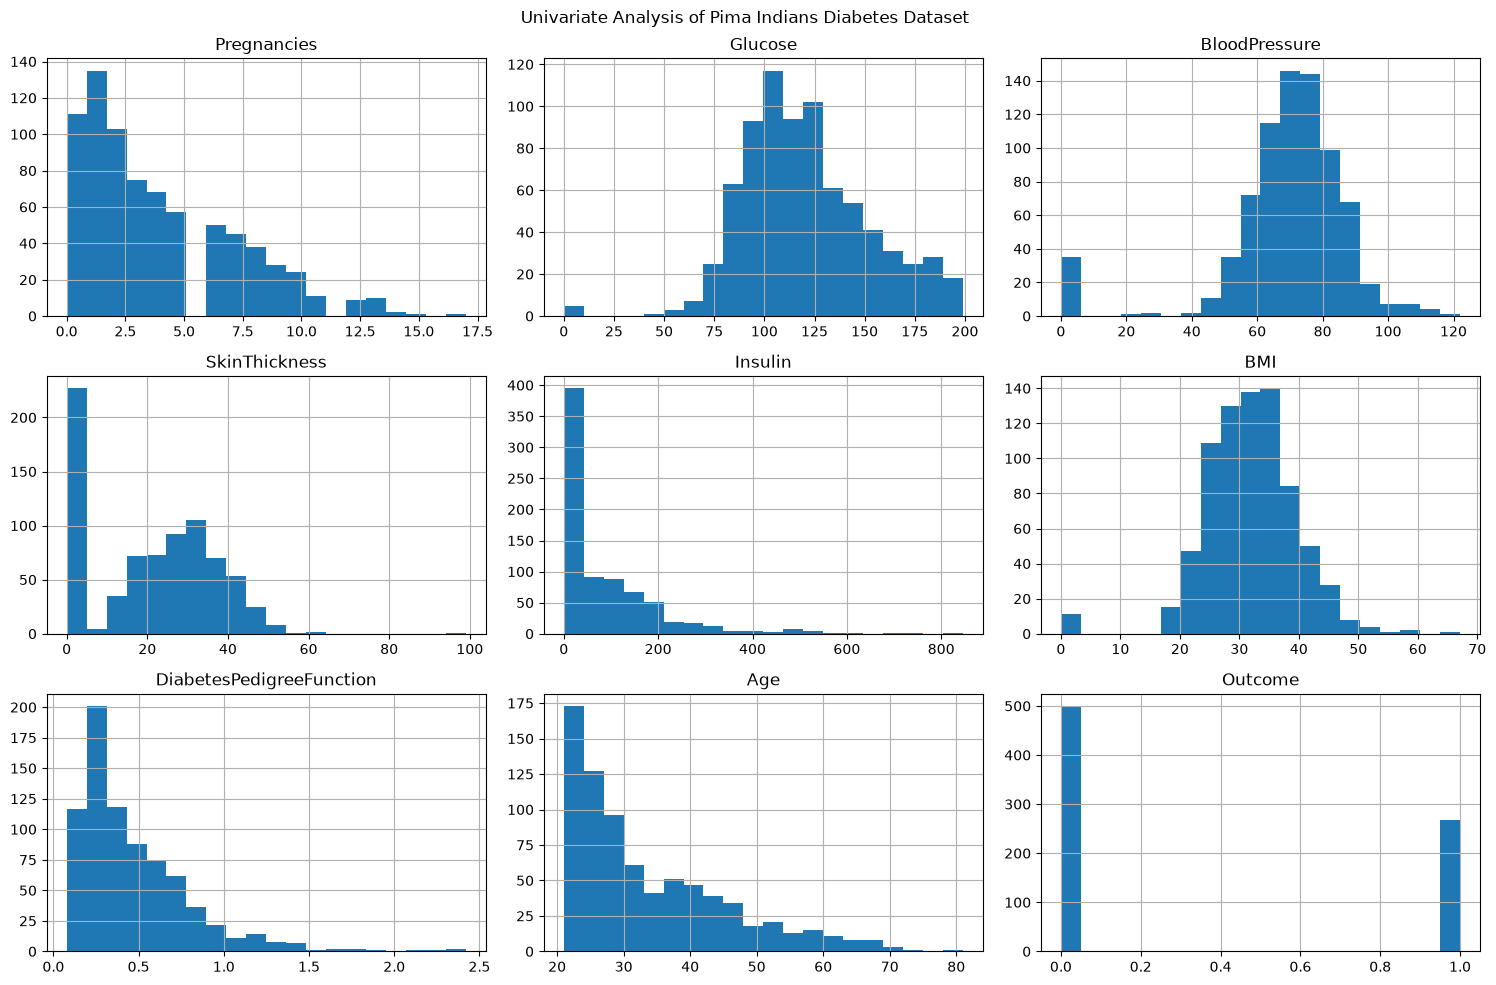

In [12]:
df.hist(figsize=(15, 10), bins=20)

plt.suptitle("Univariate Analysis of Pima Indians Diabetes Dataset")
plt.tight_layout()
plt.show()

In [13]:
X = df[["Age"]]
y = df["Glucose"]

linear_model = LinearRegression()
linear_model.fit(X, y)

y_pred = linear_model.predict(X)

print("Linear Regression Equation:")
print(f"Glucose = {linear_model.intercept_:.4f} + "
      f"{linear_model.coef_[0]:.4f} × Age")

print("\nR² Score:", r2_score(y, y_pred))

Linear Regression Equation:
Glucose = 97.0802 + 0.7164 × Age

R² Score: 0.06943979675248113


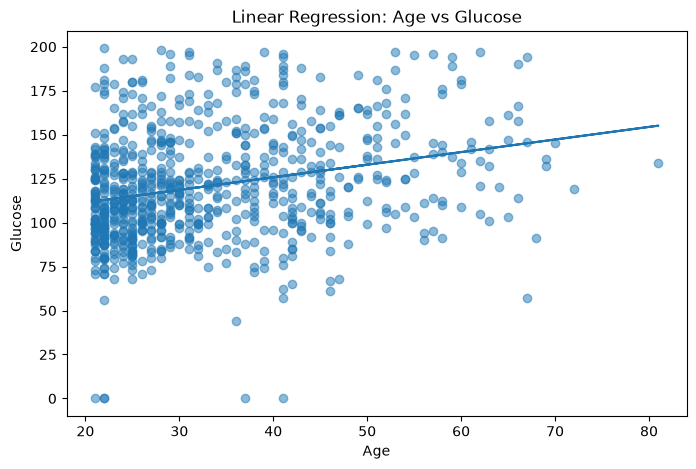

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Age"], df["Glucose"], alpha=0.5)
plt.plot(df["Age"], y_pred)

plt.xlabel("Age")
plt.ylabel("Glucose")
plt.title("Linear Regression: Age vs Glucose")

plt.show()

In [15]:
X = df[["Glucose"]]
y = df["Outcome"]

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X, y)

y_pred = logistic_model.predict(X)

accuracy = accuracy_score(y, y_pred)

print("Logistic Regression Accuracy:",
      accuracy)

Logistic Regression Accuracy: 0.74609375


In [16]:
print("Coefficient:", logistic_model.coef_[0][0])
print("Intercept:", logistic_model.intercept_[0])

Coefficient: 0.037871691000185226
Intercept: -5.349905858014434


In [17]:
print("\nClassification Report:")
print(classification_report(y, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.89      0.82       500
           1       0.70      0.49      0.57       268

    accuracy                           0.75       768
   macro avg       0.73      0.69      0.70       768
weighted avg       0.74      0.75      0.73       768



In [18]:
X = df[
    [
        "Pregnancies",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI",
        "DiabetesPedigreeFunction",
        "Age"
    ]
]

y = df["Glucose"]

multiple_model = LinearRegression()

multiple_model.fit(X, y)

y_pred = multiple_model.predict(X)

print("Multiple Linear Regression")
print("--------------------------")

print("Intercept:", multiple_model.intercept_)

print("\nCoefficients:")

for column, coefficient in zip(X.columns, multiple_model.coef_):
    print(f"{column}: {coefficient:.4f}")

print("\nR² Score:", r2_score(y, y_pred))

Multiple Linear Regression
--------------------------
Intercept: 66.24115606932634

Coefficients:
Pregnancies: 0.0589
BloodPressure: 0.0700
SkinThickness: -0.3342
Insulin: 0.1005
BMI: 0.7503
DiabetesPedigreeFunction: 6.3162
Age: 0.6453

R² Score: 0.23015423820065128


In [19]:
X = df[
    [
        "Pregnancies",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI",
        "DiabetesPedigreeFunction",
        "Age"
    ]
]

y = df["Glucose"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                Glucose   R-squared:                       0.230
Model:                            OLS   Adj. R-squared:                  0.223
Method:                 Least Squares   F-statistic:                     32.46
Date:                Thu, 17 Sep 2026   Prob (F-statistic):           1.52e-39
Time:                        02:01:19   Log-Likelihood:                -3649.8
No. Observations:                 768   AIC:                             7316.
Df Residuals:                     760   BIC:                             7353.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

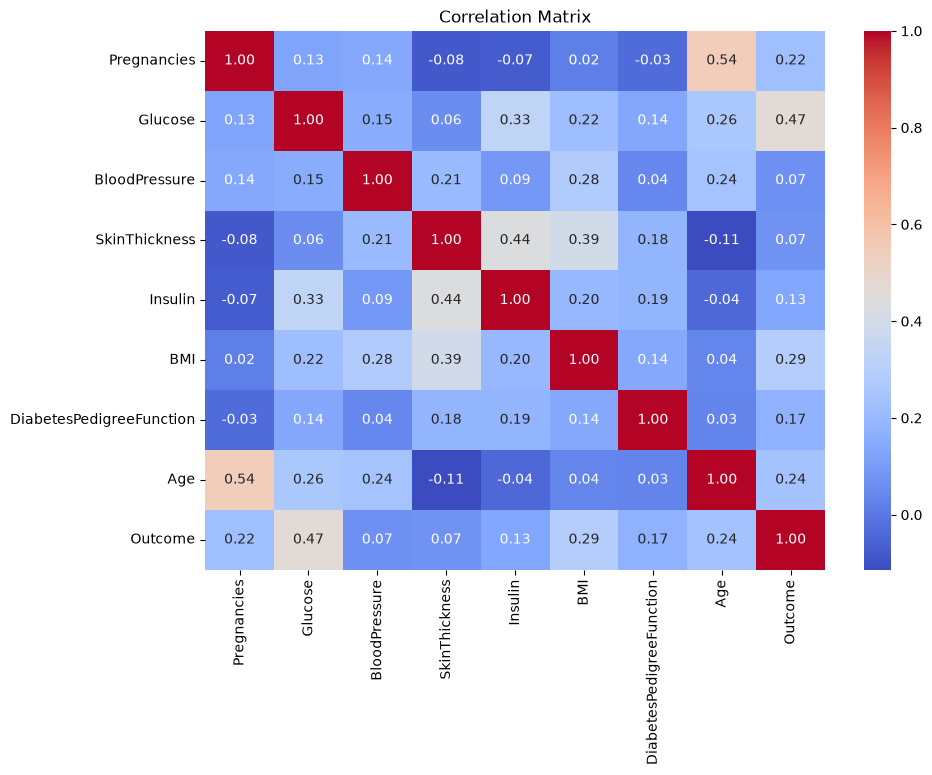

In [20]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [21]:
linear_r2 = r2_score(
    df["Glucose"],
    LinearRegression()
    .fit(df[["Age"]], df["Glucose"])
    .predict(df[["Age"]])
)

logistic_accuracy = accuracy_score(
    df["Outcome"],
    LogisticRegression(max_iter=1000)
    .fit(df[["Glucose"]], df["Outcome"])
    .predict(df[["Glucose"]])
)

multiple_r2 = r2_score(
    df["Glucose"],
    LinearRegression()
    .fit(
        df[
            [
                "Pregnancies",
                "BloodPressure",
                "SkinThickness",
                "Insulin",
                "BMI",
                "DiabetesPedigreeFunction",
                "Age"
            ]
        ],
        df["Glucose"]
    )
    .predict(
        df[
            [
                "Pregnancies",
                "BloodPressure",
                "SkinThickness",
                "Insulin",
                "BMI",
                "DiabetesPedigreeFunction",
                "Age"
            ]
        ]
    )
)

comparison = pd.DataFrame({
    "Analysis": [
        "Linear Regression",
        "Logistic Regression",
        "Multiple Regression"
    ],
    "Metric": [
        "R²",
        "Accuracy",
        "R²"
    ],
    "Result": [
        linear_r2,
        logistic_accuracy,
        multiple_r2
    ]
})

print(comparison)

              Analysis    Metric    Result
0    Linear Regression        R²  0.069440
1  Logistic Regression  Accuracy  0.746094
2  Multiple Regression        R²  0.230154
